# XS-GEM5 Tutorial 总览

XS-GEM5 是从官方 GEM5 衍生而出，并针对香山 RTL 微架构做了精细化对齐，帮助香山团队快速进行性能 feature 开发验证和评估。

本次 XS-GEM5 tutorial 将围绕 XS-GEM5 的编译、运行、性能分析和优化展开。内容包括：

- 编译 XS-GEM5；
- 运行 RISC-V 测试程序，完成基本的 XS-GEM5 仿真；
- 以 `memcpy` 为例，尝试 XS-GEM5 平台的性能分析工具；
- 尝试给 XS-GEM5 添加新特性，验证并优化 `memcpy` 带宽。

# 01-编译 XS-GEM5

> 在上手环节的整个过程中，大家如果有问题可以举手示意，我们的小伙伴会帮助大家。

本次 tutorial 固定使用 OpenXiangShan/GEM5 `8eecd224437707c4c5199bcd49ceca4a15ef8e4a` commit 版本，确保各位听众看到的配置、工具的行为都一致。为了节约时间，现场实验直接使用预编译的 `gem5.fast`。

本次实验使用的源码版本和三个运行资产如下（均已在 `assets/gem5-precompile` 中提供）：

In [18]:
%%bash
source ../env.sh

git -C "$GEM5_HOME" log -1 --format='GEM5 commit: %H%nSubject: %s'
printf '\nPre-compiled assets:\n'
ASSET=$(get_asset gem5-precompile)
for name in gem5.fast libdramsim3.so riscv64-nemu-interpreter-so; do
  printf '  %s\n' "$ASSET/$name"
done

GEM5 commit: 8eecd224437707c4c5199bcd49ceca4a15ef8e4a
Subject: mem-cache: Add tutorial L2 next-line prefetcher

Pre-compiled assets:
  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/gem5.fast
  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/libdramsim3.so
  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/riscv64-nemu-interpreter-so


- `gem5.fast`：后续 tutorial 02--04 实际运行的模拟器；
- `libdramsim3.so`：GEM5 运行时加载的 DRAMSim3 动态库；
- `riscv64-nemu-interpreter-so`：difftest 使用的 NEMU reference。

我们不进行现场编译。下面的命令全部以 `#` 注释保留，供大家参考。

In [17]:
%%bash
# 下面仅展示编译流程；这个单元不会执行任何命令。

# source ../env.sh
#
# # 使用 tutorial 固定的 GEM5 源码版本。
# cd "$GEM5_HOME"
# git checkout 8eecd224437707c4c5199bcd49ceca4a15ef8e4a
#
# # 首次编译时准备 DRAMSim3。init.sh 会下载并编译共享库。
# bash ./init.sh
#
# # --linker=mold 是可选的，可以加速编译过程，需要事先安装 mold 链接器，我们提供的 code-server 镜像中已经包含。
# # 常规开发和调试通常编译 gem5.opt，它包含更多调试信息：
# scons build/RISCV/gem5.opt --linker=mold -j8
#
# # 本次演示使用体积更小、运行更快的 gem5.fast：
# scons build/RISCV/gem5.fast --linker=mold -j8
#
# # 运行时让动态链接器能够找到刚才构建的 DRAMSim3。
# export LD_LIBRARY_PATH="$GEM5_HOME/ext/dramsim3/DRAMsim3:${LD_LIBRARY_PATH:-}"
# ./build/RISCV/gem5.opt --help
#
# # 编译完成后，模拟器会位于 `GEM5/build/RISCV/gem5.opt`
# # DRAMSim3 动态库位于 `GEM5/ext/dramsim3/DRAMsim3/libdramsim3.so`

# 02-First run：用 kmhv3.py 运行 hello

这一节尝试 GEM5 最基本的仿真流程：使用与 RTL 对齐的处理器配置 (`kmhv3.py`)，运行一个 hello RISC-V 程序。


## 运行 hello

In [11]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/02-first-run/precompiled"
rm -rf "$RUN/m5out"
mkdir -p "$RUN"

# 我们提供的 GEM5 模拟器 或 01 中编译好的 GEM5 模拟器
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
# 即将运行的 hello 程序的 bin 文件
HELLO=$(get_asset workload/hello-riscv64-xs.bin)
# 让 GEM5 能够找到 DramSim3 库
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
# 与 GEM5 在线 difftest 的 nemu
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)

cd "$GEM5_HOME"

# 使用 --raw-cpt 参数来执行非切片程序，若是切片程序则不需要这个参数
# $GEM5_HOME/configs/example/kmhv3.py 是与 RTL kmhv3 精确对齐的处理器配置
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$HELLO" \
  2>&1 | tee "$RUN/run.log" >/dev/null

tr '\r' '\n' < "$RUN/run.log"

gem5 Simulator System.  https://www.gem5.org
gem5 is copyrighted software; use the --copyright option for details.

gem5 version [DEVELOP-FOR-22.1]
gem5 compiled Oct 15 2026 10:15:43
gem5 started Oct 16 2026 16:56:07
gem5 executing on node032.bosccluster.com, pid 3617302
command line: /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/gem5.fast --outdir=/nfs/home/lixin/myworkspace/bootcamp/work/04-gem5/02-first-run/precompiled/m5out /nfs/home/lixin/myworkspace/bootcamp/GEM5/configs/example/kmhv3.py --raw-cpt --generic-rv-cpt=/nfs/home/lixin/myworkspace/bootcamp/assets/workload/hello-riscv64-xs.bin

info: Standard input is not a terminal, disabling listeners.
Checkpoint mode: Using standard FS mode with normal MMU translation
Obtained ref_so from GCBV_REF_SO:  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/riscv64-nemu-interpreter-so
Simulating single core without RVV, demanding GCPT restorer size of 0x700.
Using raw bbl /nfs/home/lixin/myworkspace/bootcamp/assets/

通过这一段 bash 脚本，XS-GEM5 仿真完成。运行结束之后可以输出 “Hello，Xiangshan!”

最后的 `m5_exit` 表示 guest 主动结束模拟。

# 03-性能分析流程：改善 memcpy 的带宽

本节使用一个 512 KB memcpy 小测试完成一次基于 XS-GEM5 平台的性能分析：

1. 关闭预取，观察 memcpy 带宽；
2. 用 Top-Down 计数器观察处理器瓶颈；
3. 使用 PerfCCT，可视化每一条指令的执行并抓取热点循环；
4. 开启 KMHv3 默认预取，对比带宽变化，确认性能收益来源。

## 1. 工作负载：512 KB memcpy

memcpy workload：将一段数据从某一块内存区域复制到另一块内存区域。

In [139]:
%%bash
source ../env.sh
ASSET=$(get_asset workload)
ls -lh "$ASSET/gem5-memcpy-riscv64-xs.bin" "$ASSET/gem5-memcpy-riscv64-xs.txt"

-rwxr-xr-x 1 lixin kunminghu 1.1M Oct 13 19:33 /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
-rw-r--r-- 1 lixin kunminghu  87K Oct 13 19:33 /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.txt


## 2. 关闭预取的 kmhv3 GEM5 模型运行 memcpy

In [140]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
# memcpy workload 的 bin 文件
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 与执行 hello 程序类似，只需要更换 --generic-rv-cpt 为对应的 workload bin 文件即可

# 使用 --no-pf 参数来关闭 prefetcher
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" --no-pf \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

Registering probe listeners for BaseO3CPU system.cpu
Registering inner cache accessors for L2CacheWrapper system.l2_wrappers
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices0
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices1
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices2
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x71f92f000000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simu

从结果上可以看到，关闭预取的 kmhv3 GEM5 模型的 memcpy 搬运数据的速度在 5076.06 MiB/s 左右

## 3. Top-Down：先判断瓶颈属于哪一侧

Top-Down[1] 是一种自顶向下、逐层分解的微架构性能分析方法，可以回答宏观问题：执行时间主要消耗在前端、错误推测、乱序执行还是内存侧

[1]: Yasin A. A top-down method for performance analysis and counters architecture\[C\]//2014 IEEE International Symposium on Performance Analysis of Systems and Software (ISPASS). IEEE, 2014: 35-44.

XS-GEM5 性能计数器支持 Top-Down 功能，可以使用 `gem5_data_proc` 仓库下的脚本来处理 memcpy 执行后的输出目录，得到 Top-Down 原始数据

In [141]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch"
INPUT="$RUN/topdown-input"
mkdir -p "$INPUT"
ln -sfn "$RUN/m5out" "$INPUT/current"

# 使用 gem5_data_proc 处理 topdown 数据
# -t --topdown-raw 参数指示 gem5_data_proc 处理 topdown 数据
export PYTHONPATH="$GEM5_DATA_PROC_HOME"
python3 "$GEM5_DATA_PROC_HOME/batch.py" \
  -s "$INPUT" -t --topdown-raw \
  -o "$RUN/topdown-raw.csv" \
  > "$RUN/topdown.log"

printf 'Top-Down data: %s\n' "$RUN/topdown-raw.csv"

Top-Down data: /nfs/home/lixin/myworkspace/bootcamp/work/04-gem5/03-perf/no-prefetch/topdown-raw.csv


这是一个 csv 文件，先查看一下里面的内容

In [142]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch"
cat "$RUN/topdown-raw.csv"

,Atomic,BpStall,CommitSquash,Cycles,DTlbStall,FetchBufferInvalid,ITlbStall,IcacheStall,InstMisPred,InstNotReady,InstSquashed,Insts,IntStall,LoadL1Bound,LoadL2Bound,LoadL3Bound,LoadMemBound,MemCommitRateLimit,MemNotReady,MemSquashed,NoStall,OtherFetchStall,OtherMemStall,OtherStall,ResumeUnblock,SerializeStall,SquashStall,StoreL1Bound,StoreL2Bound,StoreL3Bound,StoreMemBound,TrapStall,bmk,ipc,point,workload
current_0,0,0,1544,708809,0,0,0,1246,0,4714,36007,168700,0,479294,637041,68,1094703,0,141215,0,1511134,0,28,0,0,296,0,71319,0,0,0,0,current,0.238005,0,current


运行以下脚本，将以上原始 topdown 数据进行加工，便于阅读

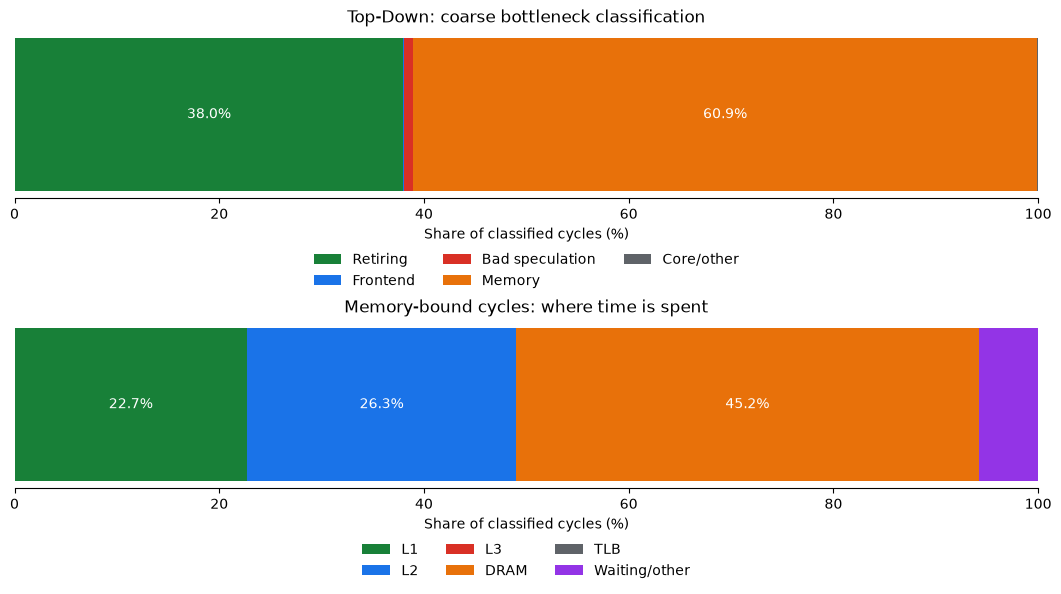

In [143]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import plot_topdown
fig, (level1, memory) = plot_topdown(
    ROOT / "work/04-gem5/03-perf/no-prefetch/topdown-raw.csv"
)
# display(level1.round(2).to_frame("percent"))
# display(memory.round(2).to_frame("percent"))
plt.show()

上图表明有 38% 是 Retiring，表示无阻塞正常退休，60.9% 集中在 Memory，进一步细分 Memory bound 可以看到 L1/L2/DRAM stall 分别占据了 22.7%/26.3%/45.2%。

因此 Top-Down 帮我们确认了：处理器的瓶颈来自于访存。

接下来我们使用 PerfCCT 工具来深入 CPU 内部分析。

## 4. PerfCCT：指令生命周期与热点循环提取

PerfCCT 将每一条指令的在乱序执行的各个生命周期时刻（例如：取值、译码、重命名、执行、写回等）和其他关键信息记录到数据库中，首先我们重新运行一遍 memcpy，这次开启 PerfCCT。

In [131]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch-perfcct"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
rm -f "$RUN/perfcct.db"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 使用 --enable-arch-db --arch-db-dump-lifetime 开启 perfcct 数据库的生成
# 使用 --arch-db-file 指定 perfcct 数据库的输出路径
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" --no-pf \
  --enable-arch-db --arch-db-dump-lifetime \
  --arch-db-file="$RUN/perfcct.db" \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

Registering inner cache accessors for L2CacheWrapper system.l2_wrappers
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices0
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices1
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices2
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x79774b000000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simulation...
build/RISCV/dev/serial/uartlite.cc:86: warn

运行结束，得到 PerfCCT 的数据库文件路径，XS-GEM5 提供了 `ClockAnalysis.py` 来处理 PerfCCT 的数据，我们先查看一下里面的原始数据

In [144]:
from pathlib import Path
import importlib
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

import gem5_tutorial_utils
gem5_tutorial_utils = importlib.reload(gem5_tutorial_utils)
from gem5_tutorial_utils import cpu_clock_period, hot_window, clock_analysis_perfcct

DB = ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/perfcct.db"
PERIOD = cpu_clock_period(ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/m5out/stats.txt")
START_PC, END_PC = 0x80000140, 0x80000192
start_cycle, end_cycle = hot_window(DB, START_PC, END_PC, PERIOD)

print(f"CPU clock period: {PERIOD} ticks/cycle")

# 查看 PerfCCT 数据库中指定范围的数据
clock_analysis_perfcct(
    ROOT / "GEM5/util/ClockAnalysis.py",
    DB,
    start_cycle,
    end_cycle,
    START_PC,
    END_PC,
    PERIOD,
    attention_pcs=(0x80000150, 0x80000166),
)

CPU clock period: 333 ticks/cycle


Reading DB: 100%|██████████| 19/19 [00:00<00:00, 100367.48it/s]

0x80000150         : ld t4, 8(a1)                   : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1577754 : g 1578087 : e 1578420 : b 1630701 : w 1630701 : c 1631367 : <<==== 
0x80000154         : ld t3, 16(a1)                  : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1577754 : g 1578087 : e 1578420 : b 1631034 : w 1631034 : c 1631700 : 
0x80000158         : ld a7, 24(a1)                  : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1577754 : g 1579086 : e 1579419 : b 1631034 : w 1631034 : c 1631700 : 
0x8000015c         : ld a6, 32(a1)                  : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1578087 : g 1578420 : e 1578753 : b 1631700 : w 1631700 : c 1632366 : 
0x80000160         : c_ld a2, 40(a1)                : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1578087 : g 1578420 : e 1578753 : b 1632033 : w 1632033 : c 1632699 : 
0x80000162         : c_ld a3, 48(a1)                : f 1521144 : d 1575090 : r 1576755 

PerfCCT 数据库里面的每一条记录存储的是指令的 pc、反汇编和在乱序流水线各个 stage 的时刻信息。

接下来继续使用 `ClockAnalysis.py` 工具来导出热点基本块。工具按出现次数排序输出热点块，本次演示展示 memcpy top1 的热点基本块。

In [145]:
%%bash
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch-perfcct"
DB="$RUN/perfcct.db"
PERIOD=$(awk '$1 == "system.cpu_clk_domain.clock" { print $2; exit }' \
  "$RUN/m5out/stats.txt")
OUTPUT="$RUN/clock-analysis-top1-inter-gap.txt"

# --period 指定 CPU 时钟周期，XS-GEM5 中 333 tick 为一个 CPU 时钟周期
# 用 `--tool bbl --inter-gap` 在完整动态指令 trace 上重建 basic block
python3 \
  "$GEM5_HOME/util/ClockAnalysis.py" \
  "$DB" \
  --period "$PERIOD" \
  --tool bbl \
  --inter-gap \
  2>/dev/null \
| awk '
/^Count:/ {
    count++
    if (count == 2) exit
}
{ print }
' \
| tee "$OUTPUT"

printf '\nExported top1 inter-gap: %s\n' "$OUTPUT"

Top 10 most common basic blocks (mode:inter-gap):

Count: 8191, Total commit time: 36.06 cycles, jumped from: 0x8000018c
Instructions:
            PC      Instruction  fetch  decode  rename  dispatch  issue   arb  read  execute  bypass  writeback  commit
0   0x80000150     ld t4, 8(a1)   1.17    3.86    0.44      0.00   0.13  0.03  1.02     1.02  169.77     169.77   30.65
1   0x80000154    ld t3, 16(a1)   0.08    3.91    0.31      0.00   0.12  0.03  0.02     0.02    2.54       2.54    2.57
2   0x80000158    ld a7, 24(a1)   0.00    4.67    0.24      0.00   0.13  0.03  0.15     0.15   -0.65      -0.65    0.20
3   0x8000015c    ld a6, 32(a1)   0.00    3.94    0.19      0.00   0.12  0.95  0.46     0.46    0.08       0.08    0.24
4   0x80000160  c_ld a2, 40(a1)   0.00    3.93    0.13      0.00   0.12  0.03  0.06     0.06    0.26       0.26    0.23
5   0x80000162  c_ld a3, 48(a1)   0.11    4.01    0.12      0.00   0.12  0.05  0.09     0.09   -1.46      -1.46    0.00
6   0x80000164  c_ld a4, 

以上结果就是 memcpy 的 top1 热点基本块：19 条指令组成的循环展开版本的内存拷贝（符合我们对 memcpy 的认知），在完整 trace 中重复执行了 8191 次。fetch decode 这些数值当前指令和上一条指令到达对应 stage 的平均时间差，先不用关心。

接下来我们继续使用 `ClockAnalysis.py` 工具提取热点基本块某一次执行时的指令执行时间轴

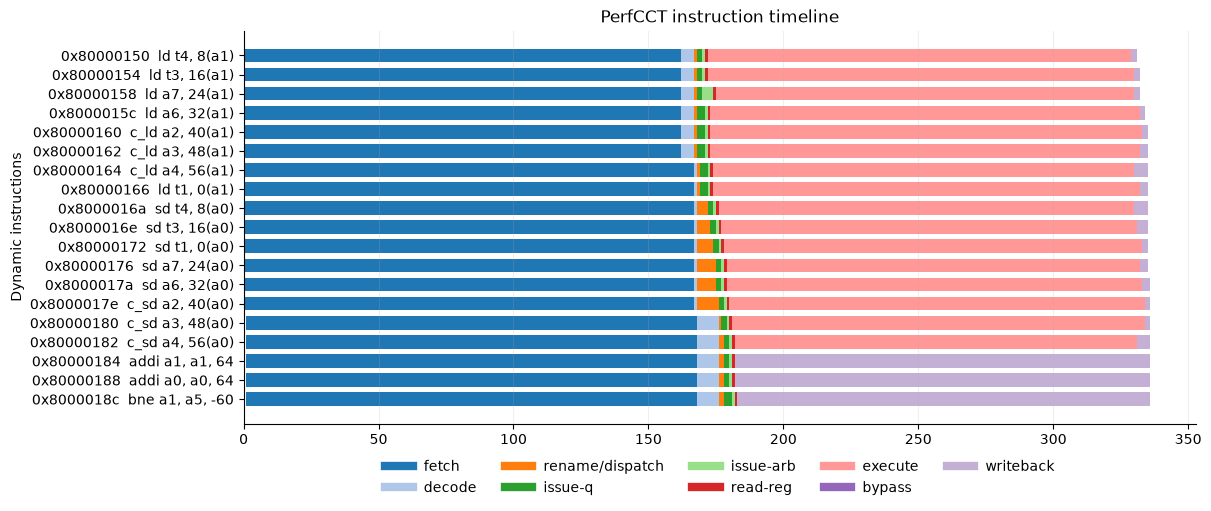

In [146]:
from gem5_tutorial_utils import plot_perfcct_timeline

# 使用 perfcct 数据库绘制指定 PC 范围内的时钟周期的可视化时间轴
fig, timeline = plot_perfcct_timeline(
    DB,
    START_PC,
    END_PC,
    period=PERIOD,
    start_cycle=start_cycle,
    end_cycle=end_cycle,
)
plt.show()

可以观察到 load store 指令的执行延迟极高，与 Topdown 中的结果呼应。

导致此现象的原因：没有打开预取，指令总是发生 cache miss，总是需要从 DDR 中获取数据，带来高额的 miss latency 开销。

预取是一个很好的解决内存墙问题的技术，我们在 kmhv3 上也进行了大量的预取优化，接下来看看开启 kmhv3 预取后的情形。

## 5. 开启 KMHv3 默认预取

In [147]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/kmhv3-default"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
rm -f "$RUN/perfcct.db"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 去掉 --no-pf 参数，就可以使用默认的开启预取版本的 kmhv3
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" \
  --enable-arch-db --arch-db-dump-lifetime \
  --arch-db-file="$RUN/perfcct.db" \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

system.l2_wrappers.slices2.inner_cache.prefetcher addTLB system.cpu.mmu.dtb
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
Registering probe listeners for Prefetcher system.l2_wrappers.slices3.inner_cache.prefetcher
system.l2_wrappers.slices3.inner_cache.prefetcher addTLB system.cpu.mmu.dtb
Registering probe listeners for Prefetcher system.l3.prefetcher
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x7a251a200000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simulation...
build/RISCV/dev/serial/uartlite.cc:86

从结果上看，开启预取后的带宽来到了 23977.37 MiB/s。

### 开启预取与关闭预取的 memcpy 带宽对比

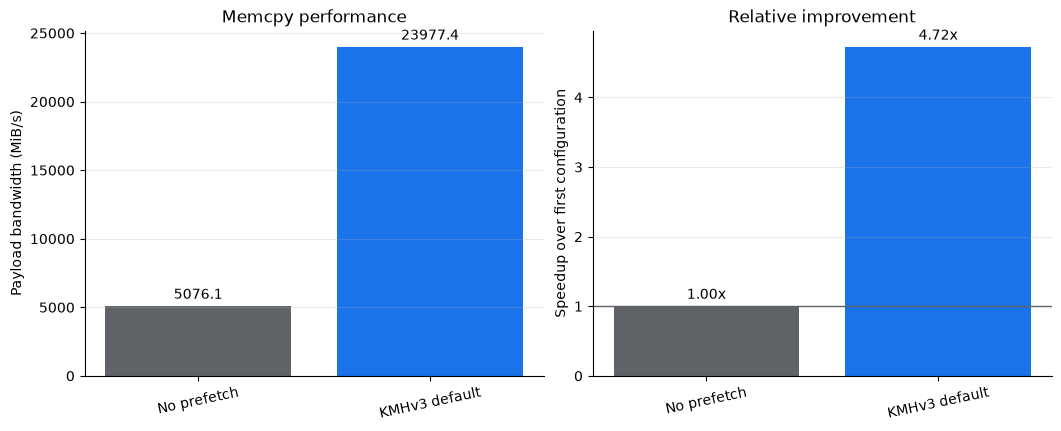

In [148]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import plot_memcpy_bandwidth
fig, results = plot_memcpy_bandwidth({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch/run.log",
    "KMHv3 default": ROOT / "work/04-gem5/03-perf/kmhv3-default/run.log",
})
# display(results[["cycles", "payload_mib_s", "traffic_mib_s", "speedup"]])
plt.show()

开启预取后 memcpy 的带宽获得了 4.72 倍的提升。

接下来，我们看看为什么开启预取能带来这么显著的效果，通过观察 load 访存指令的执行延迟的变化也许可以找到原因。

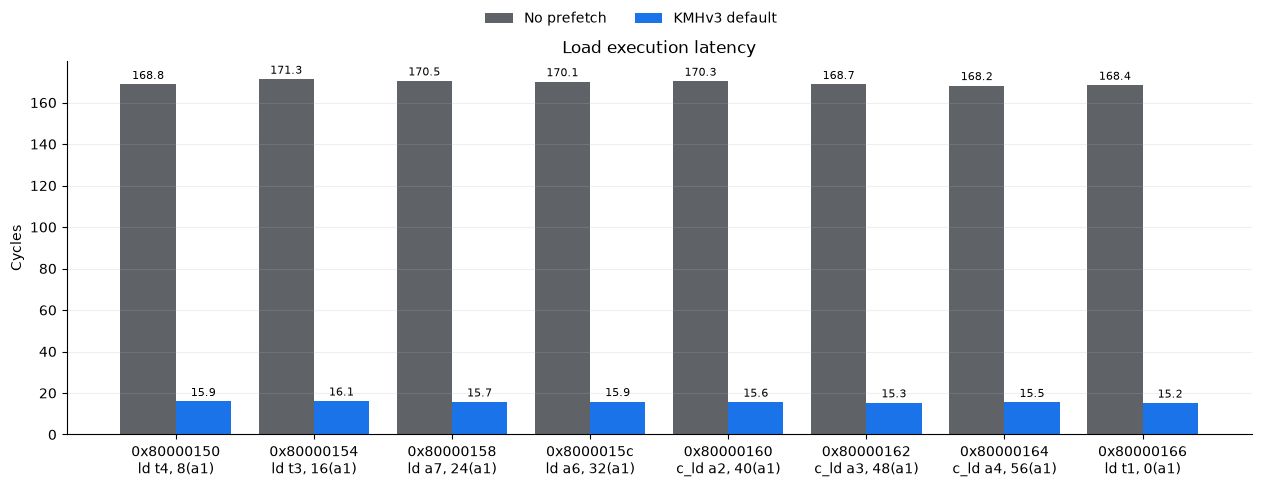

In [149]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import cpu_clock_period, plot_load_gap_comparison

PERIOD = cpu_clock_period(ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/m5out/stats.txt")
fig, gaps = plot_load_gap_comparison({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/perfcct.db",
    "KMHv3 default": ROOT / "work/04-gem5/03-perf/kmhv3-default/perfcct.db",
}, 0x80000140, 0x80000192, period=PERIOD, pc_count=8)
plt.show()

结果是符合预期的，预取开启后，数据会被提早预取到 cache 中，load 的执行延迟会先缩短，流水线提交停顿随之减少，最终反映为更高的 memcpy 带宽。

### 开启预取后的 Instruction timeline

最后我们看一下开启预取后的热点基本块某次执行时的指令 timeline。

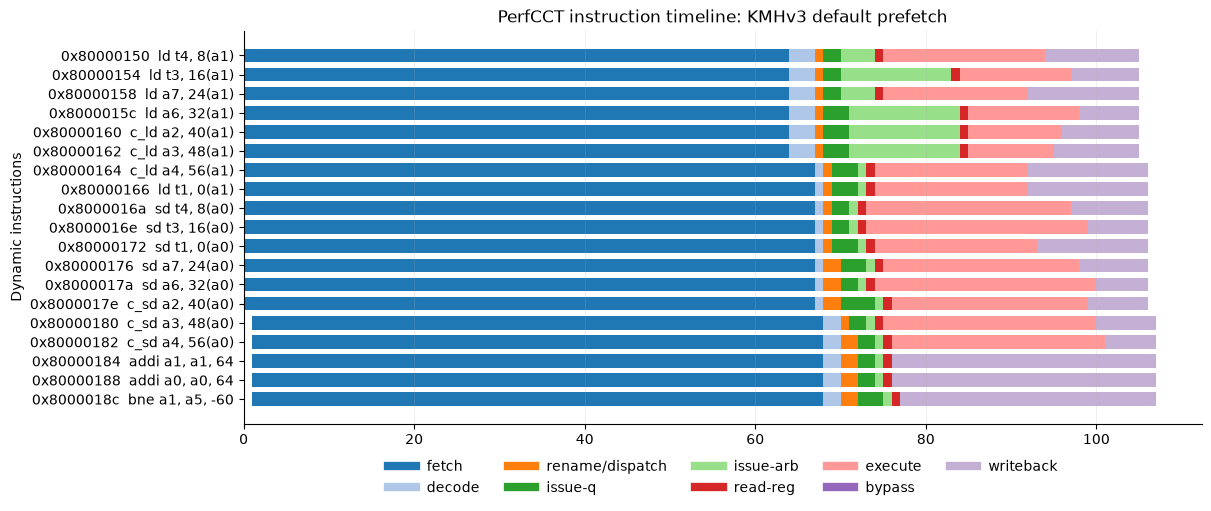

In [150]:
from gem5_tutorial_utils import plot_perfcct_timeline

fig, _ = plot_perfcct_timeline(
    ROOT / "work/04-gem5/03-perf/kmhv3-default/perfcct.db",
    START_PC,
    END_PC,
)
fig.axes[0].set_title("PerfCCT instruction timeline: KMHv3 default prefetch")
plt.show()

与关闭预取时的 timeline 相比，横轴周期数明显减少，load 的执行延迟也显著缩短，印证了预取的作用。

本节从微架构优化的角度对 memcpy 进行了程序特性分析和微架构瓶颈定位，也看到了 kmhv3 预取器的显著优化效果，下一节我们将尝试添加一个自己设计的预取器到 XS-GEM5 中。

# 04-Case study：给 GEM5 增加 L2 NextLinePrefetcher

这一节展示如何把一个新的预取部件接入 GEM5。代码已经作为提交 `8eecd224437707c4c5199bcd49ceca4a15ef8e4a` 合入了 XS-GEM5，不需要重新编译。

## 1. 阅读 L2 NextLinePrefetcher 实现

In [29]:
%%bash
source ../env.sh

COMMIT=8eecd224437707c4c5199bcd49ceca4a15ef8e4a
git -C "$GEM5_HOME" show --stat --oneline "$COMMIT"

printf '\n1) Core next-line algorithm:\n'
git -C "$GEM5_HOME" show "$COMMIT:src/mem/cache/prefetch/next_line.cc" \
  | sed -n '/NextLine::calculatePrefetch/,/^}/p'

printf '\n2) SimObject registration:\n'
git -C "$GEM5_HOME" show "$COMMIT:src/mem/cache/prefetch/Prefetcher.py" \
  | sed -n '489,495p'

printf '\n3) Apply in kmhv3.py:\n'
git -C "$GEM5_HOME" show "$COMMIT:configs/example/kmhv3.py" \
  | sed -n '205,215p' 

8eecd22 mem-cache: Add tutorial L2 next-line prefetcher
 configs/common/Options.py            |  4 +++
 configs/common/PrefetcherConfig.py   |  9 +++++-
 configs/common/xiangshan.py          |  8 ++++--
 configs/example/kmhv3.py             | 11 ++++++++
 src/mem/Request.py                   |  1 +
 src/mem/cache/prefetch/Prefetcher.py |  7 +++++
 src/mem/cache/prefetch/SConscript    |  3 +-
 src/mem/cache/prefetch/next_line.cc  | 53 ++++++++++++++++++++++++++++++++++
 src/mem/cache/prefetch/next_line.hh  | 55 ++++++++++++++++++++++++++++++++++++
 9 files changed, 147 insertions(+), 4 deletions(-)

1) Core next-line algorithm:
NextLine::calculatePrefetch(const PrefetchInfo &pfi,
                            std::vector<AddrPriority> &addresses)
{
    addresses.emplace_back(blockAddress(pfi.getAddr()) + blkSize, 0,
                           PrefetchSourceType::NextLine);
}

2) SimObject registration:
class NextLinePrefetcher(QueuedPrefetcher):
    type = 'NextLinePrefetcher'
    cxx_cla

主要的改动为三个方面：

+ 核心算法是把当前地址对齐到 cache line，再请求下一条 line。

+ 将 `NextLinePrefetcher` 注册为一个 `QueuedPrefetcher` SimObject；

+ 将 `NextLinePrefetcher` 挂载到 L2 cache 中，并提供一个 `--l2-next-line-only` 开关表示仅开启 `NextLinePrefetcher`

## 2. 使用开启 L2 NextLinePrefetcher 的 XS-GEM5 运行 memcpy

In [30]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/04-case-study-prefetcher/l2-next-line"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
rm -f "$RUN/perfcct.db"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 使用 --l2-next-line-only 参数仅启用 L2 Cache 的 Next-Line Prefetcher
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" \
  --l2-next-line-only \
  --enable-arch-db --arch-db-dump-lifetime \
  --arch-db-file="$RUN/perfcct.db" \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

Registering probe listeners for Prefetcher system.l2_wrappers.slices2.inner_cache.prefetcher
system.l2_wrappers.slices2.inner_cache.prefetcher addTLB system.cpu.mmu.dtb
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
Registering probe listeners for Prefetcher system.l2_wrappers.slices3.inner_cache.prefetcher
system.l2_wrappers.slices3.inner_cache.prefetcher addTLB system.cpu.mmu.dtb
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x7de7fac00000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simulation...
build/RI

`NextLinePrefetcher` 的 memcpy 带宽是 6002.23 MiB/s。

## 3. 与关闭预取的 baseline 进行带宽比较

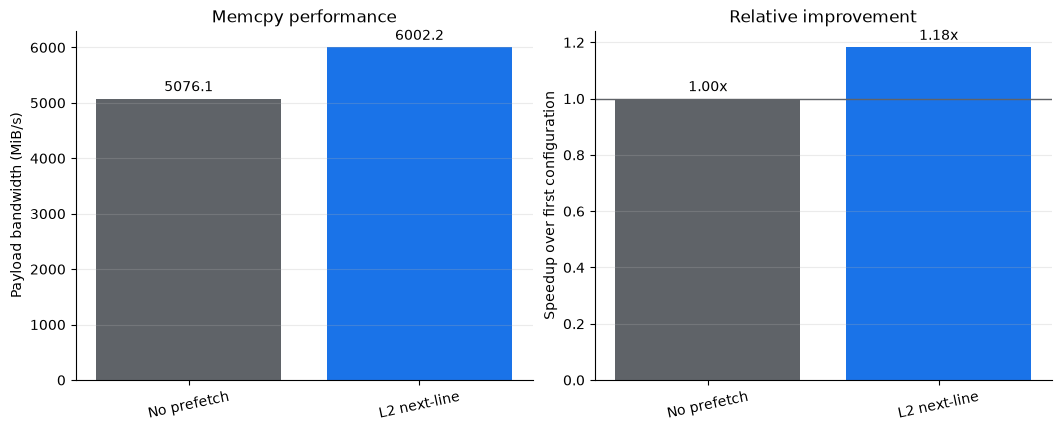

In [31]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import plot_memcpy_bandwidth
fig, results = plot_memcpy_bandwidth({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch/run.log",
    "L2 next-line": ROOT / "work/04-gem5/04-case-study-prefetcher/l2-next-line/run.log",
})
# display(results[["cycles", "payload_mib_s", "speedup"]])
plt.show()

尽管 `NextLinePrefetcher` 不如 kmhv3 的预取器对 memcpy 带宽提升显著，但是能够验证 `NextLinePrefetcher` 设计的有效性。

## 4. 总结

本次 XS-GEM5 tutorial 给大家演示了如何编译和使用 XS-GEM5，并以 memcpy 这个测试为例给大家演示了我们 XS-GEM5 平台的性能分析工具，给大家展示了 kmhv3 预取器和简单的 L2 NextLine 预取器对 memcpy 性能改善的效果。

虽然 memcpy 是一个很简单的小测试，但是性能分析和优化思路是一致的，不管是对复杂的 SPECCPU 程序甚至黑盒应用 trace 进行性能优化，都可以按照从 Top-Down 瓶颈分析、热点基本块分析、关键问题指令执行行为分析、定位优化点，到设计优化方案，并进行验证闭环这样的思路进行。

**XS-GEM5 平台提供了完善的性能分析工具和流程，欢迎大家使用 XS-GEM5 进行更多的研究和探索！**